# How does a computer find the lowest point of a landscape it can't see?

The companion notebook to `notes.pdf`. You feel a slope from two heights, walk down a one-knob valley in exact
fractions, try five step sizes and see the one number that decides them, walk a two-knob landscape into a deep
valley (or a shallow one), find the step size past which it never settles, and then let gradient descent fit a
line to 12 apartments, with the knobs chosen well and chosen badly.

Nothing here is timed: every number is a position, a slope, a height or a count of steps, the same on every
machine. Standard library only; matplotlib is optional (every picture is also printed as numbers). It runs in a
few seconds. Set `FULL = True` to run the long walk of section 6 all the way (738,888 steps, a few
seconds more).

In [1]:
FULL = False                       # True: the long walk of section 6 runs to the end (a few seconds more)
LONG_CAP = 2_000_000 if FULL else 100_000

import math
from fractions import Fraction as Fr

try:
    import matplotlib.pyplot as plt
except ImportError:                # the pictures are optional; their numbers are printed too
    plt = None

## 1. One knob: feeling the slope

The valley is \(f(x) = (x - 2)^2 + 1\), bottom at 2. The walker stands at
6 and can only ask for heights. Two heights a tiny step \(h\) apart, divided by the distance
between them, give the slope. Watch it settle on 8 as \(h\) shrinks: the two-sided
measurement is exact for this curve at every \(h\), the one-sided one (only to the right) only gets close.

In [2]:
def f(x):
    return (x - 2) ** 2 + 1


def slope(x):                      # the formula (the derivative)
    return 2 * (x - 2)


x = 6
for h in [1, 0.1, 0.01, 0.001]:
    two_sided = (f(x + h) - f(x - h)) / (2 * h)
    one_sided = (f(x + h) - f(x)) / h
    print(f"h = {h:<6} two heights either side: {two_sided:.6f}   right side only: {one_sided:.6f}")
print("the formula 2 * (x - 2):", slope(x))

h = 1      two heights either side: 8.000000   right side only: 9.000000
h = 0.1    two heights either side: 8.000000   right side only: 8.100000
h = 0.01   two heights either side: 8.000000   right side only: 8.010000
h = 0.001  two heights either side: 8.000000   right side only: 8.001000
the formula 2 * (x - 2): 8


The rule is \(x_{\text{new}} = x - \eta \cdot \text{slope}\). With \(\eta = 1/4\) our run went
6, 4, 3, 2.5,
2.25. In exact fractions you can see each step halve the distance to the bottom, and the step
shrink with the slope, with no rounding anywhere.

In [3]:
x, eta = Fr(6), Fr(1, 4)
print(f"{'step':>4} {'x':>8} {'slope':>6} {'step taken':>10} {'distance to 2':>14}")
for k in range(7):
    s = slope(x)
    print(f"{k:>4} {str(x):>8} {str(s):>6} {str(eta * s):>10} {str(abs(x - 2)):>14}")
    x = x - eta * s

step        x  slope step taken  distance to 2
   0        6      8          2              4
   1        4      4          1              2
   2        3      2        1/2              1
   3      5/2      1        1/4            1/2
   4      9/4    1/2        1/8            1/4
   5     17/8    1/4       1/16            1/8
   6    33/16    1/8       1/32           1/16


## 2. The step size: one number decides

One step does \(x - 2 \to (1 - 2\eta)(x - 2)\): it multiplies the distance to the bottom by \(1 - 2\eta\). Our run
counted the steps to get within 0.01 of the bottom: 57
for \(\eta = 1/20\), 9 for \(1/4\),
9 for \(3/4\), and never for 1 (it bounces between
6 and -2) or \(11/10\) (it flies off).

eta = 1/20  factor 1 - 2*eta = 9/10  first positions 6, 5.6, 5.24, 4.916, 4.6244, 4.36196       steps to 0.01: 57
eta = 1/4   factor 1 - 2*eta = 1/2   first positions 6, 4, 3, 2.5, 2.25, 2.125                  steps to 0.01: 9
eta = 3/4   factor 1 - 2*eta = -1/2  first positions 6, 0, 3, 1.5, 2.25, 1.875                  steps to 0.01: 9
eta = 1     factor 1 - 2*eta = -1    first positions 6, -2, 6, -2, 6, -2                        steps to 0.01: never
eta = 11/10 factor 1 - 2*eta = -6/5  first positions 6, -2.8, 7.76, -4.912, 10.2944, -7.95328   steps to 0.01: never


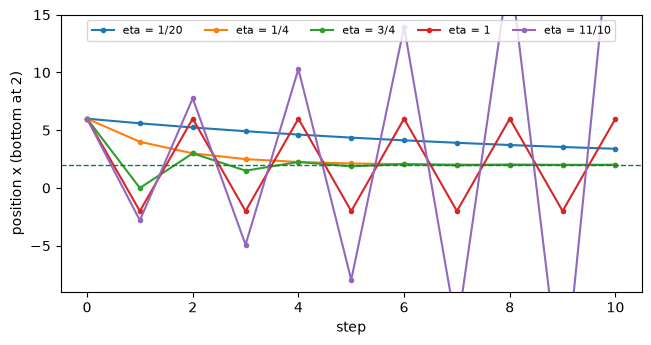

In [4]:
def steps_within(eta, tol=Fr(1, 100), cap=10_000):
    x = Fr(6)
    for k in range(cap + 1):
        if abs(x - 2) <= tol:
            return k
        if abs(x - 2) > 10 ** 6:
            return None
        x = x - eta * slope(x)
    return None


RATES = [Fr(1, 20), Fr(1, 4), Fr(3, 4), Fr(1), Fr(11, 10)]
walks = {}
for eta in RATES:
    xs = [Fr(6)]
    for _ in range(10):
        xs.append(xs[-1] - eta * slope(xs[-1]))
    walks[eta] = xs
    n = steps_within(eta)
    print(f"eta = {str(eta):<5} factor 1 - 2*eta = {str(1 - 2 * eta):<5} "
          f"first positions {', '.join(f'{float(v):g}' for v in xs[:6]):<42} steps to 0.01: {'never' if n is None else n}")

if plt:
    fig, ax = plt.subplots(figsize=(7.5, 3.6))
    for eta, xs in walks.items():
        ax.plot(range(len(xs)), [float(v) for v in xs], "o-", ms=3, label=f"eta = {eta}")
    ax.axhline(2, color="#1E7346", lw=1, ls="--")
    ax.set_ylim(-9, 15)
    ax.set_xlabel("step")
    ax.set_ylabel("position x (bottom at 2)")
    ax.legend(fontsize=8, ncol=5, loc="upper center")
    plt.show()

## 3. Two knobs: the gradient and two valleys

The landscape of the video: a gentle bowl, a deep valley, a shallow valley and a hill. At the start
\((-1.9, 2.5)\) the two slopes were \(-0.301\) and
\(0.399\): the gradient, an arrow of length 0.4999 pointing uphill.
The walk steps against it. With \(\eta = 0.6\) our run reached the deep bottom (height
-0.866) in 25 steps; from \((-2.6, 0.4)\)
it settled in the shallow one (height -0.369) in 10.

slopes at the start: -0.301252, 0.398871   felt from nearby heights: -0.301252, 0.398871
the gradient's length (steepness): 0.499851
eta 0.6 from (-1.9, 2.5): 25 steps, ends at (1.1116, 0.5540), height -0.8662
eta 0.6 from (-2.6, 0.4): 10 steps, ends at (-1.2757, -1.0029), height -0.3686


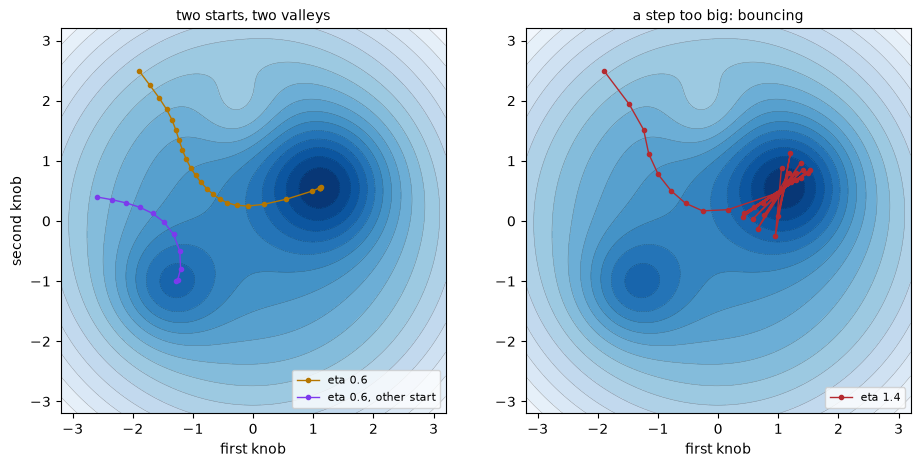

In [5]:
BOWL = 0.08
BUMPS = [(-1.0, 1.2, 0.6, 1.0), (-0.6, -1.4, -1.1, 0.7), (0.35, -0.2, 1.8, 0.5)]   # (height, x, y, width^2)


def land(x, y):
    return BOWL * (x * x + y * y) + sum(a * math.exp(-((x - cx) ** 2 + (y - cy) ** 2) / w) for a, cx, cy, w in BUMPS)


def gradient(x, y):
    gx, gy = 2 * BOWL * x, 2 * BOWL * y
    for a, cx, cy, w in BUMPS:
        e = a * math.exp(-((x - cx) ** 2 + (y - cy) ** 2) / w)
        gx += e * (-2 * (x - cx) / w)
        gy += e * (-2 * (y - cy) / w)
    return gx, gy


def walk(x, y, eta, tol=1e-3, cap=400, box=3.2):
    """Step against the gradient until the ground is flat (arrow < tol), cap steps, or the walker leaves the map."""
    path = [(x, y)]
    for _ in range(cap):
        gx, gy = gradient(x, y)
        if math.hypot(gx, gy) < tol:
            break
        x, y = x - eta * gx, y - eta * gy
        path.append((x, y))
        if abs(x) > box or abs(y) > box:
            break
    return path


gx, gy = gradient(-1.9, 2.5)
d = 1e-6
print(f"slopes at the start: {gx:.6f}, {gy:.6f}   felt from nearby heights: "
      f"{(land(-1.9 + d, 2.5) - land(-1.9 - d, 2.5)) / (2 * d):.6f}, {(land(-1.9, 2.5 + d) - land(-1.9, 2.5 - d)) / (2 * d):.6f}")
print(f"the gradient's length (steepness): {math.hypot(gx, gy):.6f}")
hero, other, big = walk(-1.9, 2.5, 0.6), walk(-2.6, 0.4, 0.6), walk(-1.9, 2.5, 1.4, cap=30)
for name, p in (("eta 0.6 from (-1.9, 2.5)", hero), ("eta 0.6 from (-2.6, 0.4)", other)):
    x, y = p[-1]
    print(f"{name}: {len(p) - 1} steps, ends at ({x:.4f}, {y:.4f}), height {land(x, y):.4f}")

if plt:
    n = 121
    g = [-3.2 + 6.4 * i / (n - 1) for i in range(n)]
    Z = [[land(x, y) for x in g] for y in g]
    fig, axes = plt.subplots(1, 2, figsize=(11, 5))
    for ax, walks_, title in ((axes[0], [(hero, "#B57600", "eta 0.6"), (other, "#7C3AED", "eta 0.6, other start")],
                               "two starts, two valleys"),
                              (axes[1], [(big, "#B42A30", "eta 1.4")], "a step too big: bouncing")):
        ax.contourf(g, g, Z, levels=24, cmap="Blues_r")
        ax.contour(g, g, Z, levels=24, colors="k", linewidths=0.3, alpha=0.4)
        for p, c, lab in walks_:
            ax.plot([q[0] for q in p], [q[1] for q in p], "o-", ms=3, lw=1, color=c, label=lab)
        ax.set_title(title, fontsize=10)
        ax.set_aspect("equal")
        ax.legend(loc="lower right", fontsize=8)
        ax.set_xlabel("first knob")
    axes[0].set_ylabel("second knob")
    plt.show()

## 4. Where the step size stops working

Near a bottom every valley is a bowl. Along a direction that curves by \(c\), a step multiplies the distance by
\(1 - \eta c\), so the walk can settle only while \(\eta < 2/c\). The deep valley's steepest curvature is
2.163, so the limit is 0.9247: "about 0.92"
in the video. Below, the curvatures come from slopes a tiny step apart (the Hessian), and a scan of step sizes from
the video's start shows the switch right at the limit. At \(\eta = 1.4\) our run fell into the deep
valley at step 9 and was still bouncing after 2,000 steps.

In [6]:
def curvatures(x, y, d=1e-5):
    (ax_, ay), (bx, by) = gradient(x + d, y), gradient(x - d, y)
    (cx, cy), (ex, ey) = gradient(x, y + d), gradient(x, y - d)
    a, b, c, e = (ax_ - bx) / (2 * d), (cx - ex) / (2 * d), (ay - by) / (2 * d), (cy - ey) / (2 * d)
    tr, det = a + e, a * e - b * c
    disc = math.sqrt(max(tr * tr / 4 - det, 0))
    return tr / 2 - disc, tr / 2 + disc


bx, by = walk(-1.9, 2.5, 0.3, tol=1e-12, cap=20_000)[-1]       # the deep bottom, to plenty of digits
lo, hi = curvatures(bx, by)
print(f"deep bottom ({bx:.6f}, {by:.6f}): curvatures {lo:.6f} and {hi:.6f}, limit 2 / {hi:.6f} = {2 / hi:.4f}\n")
print(f"{'eta':>5} {'steps':>6}  what happens")
for eta in [0.1, 0.3, 0.6, 0.8, 0.9, 0.92, 0.93, 1.0, 1.4, 2.0]:
    p = walk(-1.9, 2.5, eta, cap=5000)
    x, y = p[-1]
    if math.hypot(*gradient(x, y)) < 1e-3:
        what = f"settles, height {land(x, y):.4f}"
    elif max(abs(x), abs(y)) > 3.2:
        what = "leaves the map"
    else:
        what = "still bouncing after 5,000 steps"
    print(f"{eta:>5} {len(p) - 1:>6}  {what}")

deep bottom (1.111517, 0.553970): curvatures 2.100403 and 2.162813, limit 2 / 2.162813 = 0.9247

  eta  steps  what happens
  0.1    143  settles, height -0.8662
  0.3     46  settles, height -0.8662
  0.6     25  settles, height -0.8662
  0.8     31  settles, height -0.8662
  0.9     94  settles, height -0.8662
 0.92    418  settles, height -0.8662
 0.93   5000  still bouncing after 5,000 steps
  1.0   5000  still bouncing after 5,000 steps
  1.4   5000  still bouncing after 5,000 steps
  2.0   5000  still bouncing after 5,000 steps


## 5. Teaching a line

12 apartments in Lisbon, made up from a fixed seed (not real listings). The line has two knobs:
\(a\), the rent at 75 m² (the average size), and \(s\), the extra rent per 10 m². The error is the
average squared miss; its root is the typical miss. Our run: from a flat line at 900 euros (typical
miss 603.8) to 132.9 in 40 steps with
\(\eta = 0.08\), ending 0.46 euros from the exact least-squares line,
\(a = 4175/3\), \(s = 373300/2209\).

apartments (m^2, euros): [(48, 1010), (52, 1120), (56, 1320), (62, 1090), (63, 990), (68, 1090), (71, 1250), (87, 1600), (93, 1610), (95, 1690), (98, 1810), (107, 2120)]
exact best line: a = 4175/3 = 1391.6667, s = 373300/2209 = 168.9905, typical miss 132.88
step  0: a =   900.00  s =    0.00  typical miss  603.8
step  1: a =   978.67  s =   99.55  typical miss  453.9
step  2: a =  1044.75  s =  140.45  typical miss  375.5
step  5: a =  1186.05  s =  167.01  typical miss  244.8
step 10: a =  1305.67  s =  168.97  typical miss  158.3
step 20: a =  1376.63  s =  168.99  typical miss  133.7
step 40: a =  1391.21  s =  168.99  typical miss  132.9
gap after 40 steps: a -0.46 euros, predicted -0.46 (each step multiplies it by 0.84)


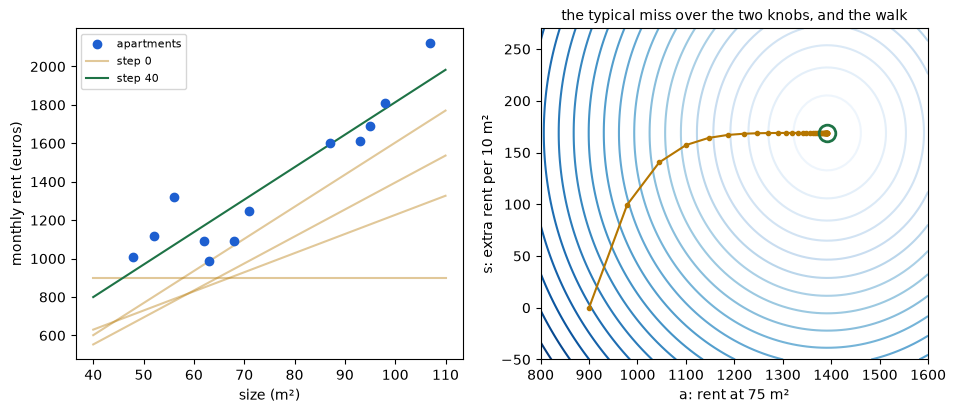

In [7]:
import random


def apartments(seed=1847):
    """Eleven sizes from 38 to 112 m^2 and a twelfth that makes the average exactly 75; rent = 16.5/m^2 + 150 + noise."""
    rng = random.Random(seed)
    while True:
        sizes = [rng.randrange(38, 113) for _ in range(11)]
        last = 900 - sum(sizes)
        if 38 <= last <= 112 and last not in sizes:
            sizes.append(last)
            break
    rents = [int(round((16.5 * m + 150 + rng.gauss(0, 90)) / 10) * 10) for m in sizes]
    return sorted(zip(sizes, rents))


APTS = apartments()
TABLE = [(48, 1010), (52, 1120), (56, 1320), (62, 1090), (63, 990), (68, 1090),
         (71, 1250), (87, 1600), (93, 1610), (95, 1690), (98, 1810), (107, 2120)]
if APTS != TABLE:                  # a different random module: use the video's table
    print("note: this Python made different apartments; using the table from the video")
    APTS = TABLE
sizes, rents = [m for m, _ in APTS], [v for _, v in APTS]
n = len(APTS)
u = [(m - 75) / 10 for m in sizes]
print("apartments (m^2, euros):", APTS)


def error(a, s):
    return sum((a + s * t - v) ** 2 for t, v in zip(u, rents)) / n


def slopes(a, s):
    miss = [a + s * t - v for t, v in zip(u, rents)]
    return 2 * sum(miss) / n, 2 * sum(q * t for q, t in zip(miss, u)) / n


U = [Fr(m - 75, 10) for m in sizes]
var_u = sum(t * t for t in U) / n
best_a = Fr(sum(rents), n)
best_s = sum(t * v for t, v in zip(U, rents)) / n / var_u
print(f"exact best line: a = {best_a} = {float(best_a):.4f}, s = {best_s} = {float(best_s):.4f}, "
      f"typical miss {math.sqrt(error(float(best_a), float(best_s))):.2f}")

eta, (a, s) = 0.08, (900.0, 0.0)
path = []
while True:
    path.append((a, s))
    if abs(a - float(best_a)) < 0.5 and abs(s - float(best_s)) < 0.05:
        break
    ga, gs = slopes(a, s)
    a, s = a - eta * ga, s - eta * gs
for k in [0, 1, 2, 5, 10, 20, len(path) - 1]:
    a, s = path[k]
    print(f"step {k:>2}: a = {a:8.2f}  s = {s:7.2f}  typical miss {math.sqrt(error(a, s)):6.1f}")
print(f"gap after {len(path) - 1} steps: a {path[-1][0] - float(best_a):+.2f} euros, "
      f"predicted {(900 - float(best_a)) * (1 - 2 * eta) ** (len(path) - 1):+.2f} (each step multiplies it by {1 - 2 * eta:.2f})")

if plt:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.3))
    ax1.scatter(sizes, rents, color="#1D5FD0", zorder=3, label="apartments")
    for k in (0, 1, 2, 5, len(path) - 1):
        a, s = path[k]
        last = k == len(path) - 1
        ax1.plot([40, 110], [a + s * (40 - 75) / 10, a + s * (110 - 75) / 10], color="#1E7346" if last else "#B57600",
                 alpha=1 if last else 0.4, label=f"step {k}" if k in (0, len(path) - 1) else None)
    ax1.set_xlabel("size (m²)")
    ax1.set_ylabel("monthly rent (euros)")
    ax1.legend(fontsize=8)
    A = [800 + i * 10 for i in range(81)]
    S = [-50 + i * 4 for i in range(81)]
    ax2.contour(A, S, [[math.sqrt(error(a, s)) for a in A] for s in S], levels=20, cmap="Blues")
    ax2.plot([p[0] for p in path], [p[1] for p in path], "o-", ms=3, color="#B57600")
    ax2.plot(float(best_a), float(best_s), "o", mfc="none", mec="#1E7346", ms=12, mew=2)
    ax2.set_xlabel("a: rent at 75 m²")
    ax2.set_ylabel("s: extra rent per 10 m²")
    ax2.set_title("the typical miss over the two knobs, and the walk", fontsize=10)
    plt.show()

## 6. The usual knobs: a long thin valley

Write the same line as rent \(= b + w \cdot \text{size}\). The error bowl's two curvatures become
0.122843 and 11,988: 97,590 times more curved one
way. With a safe step for the steep direction, each step shrinks the gap along the valley by a factor of only
\(1 - 1/97{,}590\), and our run needed 738,888 steps to get
within half a euro. The cell prints the gap as the walk crawls (with `FULL = False` it stops after
100,000 steps).

In [8]:
xbar = sum(sizes) / n
sx2 = sum(m * m for m in sizes) / n
tr, det = 2 + 2 * sx2, 4 * sx2 - (2 * xbar) ** 2
lo, hi = tr / 2 - math.sqrt(tr * tr / 4 - det), tr / 2 + math.sqrt(tr * tr / 4 - det)
print(f"curvatures {lo:.6f} and {hi:.2f}: {hi / lo:,.0f} times more curved across than along")
step = 1 / hi
best_b, best_w = float(best_a - best_s * Fr(75, 10)), float(best_s / 10)
b, w = 900.0, 0.0
checkpoints = {1, 10, 100, 1_000, 10_000, 100_000, 500_000}
for k in range(LONG_CAP + 1):
    if k in checkpoints:
        print(f"step {k:>7,}: b = {b:9.3f} (best {best_b:.3f})   w = {w:7.4f} (best {best_w:.4f})")
    if abs(b - best_b) < 0.5 and abs(w - best_w) < 0.005:
        print(f"within half a euro after {k:,} steps")
        break
    res = [b + w * m - v for m, v in zip(sizes, rents)]
    gb, gw = 2 * sum(res) / n, 2 * sum(q * m for q, m in zip(res, sizes)) / n
    b, w = b - step * gb, w - step * gw
else:
    print(f"not there after {LONG_CAP:,} steps (set FULL = True to run it to the end)")

curvatures 0.122843 and 11988.21: 97,590 times more curved across than along
step       1: b =   900.082 (best 124.238)   w =  7.1898 (best 16.8990)
step      10: b =   900.010 (best 124.238)   w =  7.1907 (best 16.8990)
step     100: b =   899.295 (best 124.238)   w =  7.1997 (best 16.8990)
step   1,000: b =   892.180 (best 124.238)   w =  7.2887 (best 16.8990)
step  10,000: b =   824.526 (best 124.238)   w =  8.1354 (best 16.8990)


step 100,000: b =   402.694 (best 124.238)   w = 13.4143 (best 16.8990)
not there after 100,000 steps (set FULL = True to run it to the end)


## Your turn

Two experiments, each changing one thing.

1. **A step size between the limits.** For the line, \(a\)'s limit is 1 and \(s\)'s is
   0.271616. Set `eta = 0.3` below: which knob settles, which one runs away, and what does the line do?
2. **Centre the sizes, but don't scale them.** Measure size from 75 m² in single square metres (`u = m - 75`). The
   knobs still don't mix, but how much more curved is the bowl one way now, and how many steps does the same walk
   need with a safe step?

In [9]:
eta = 0.3                          # experiment 1: try 0.25, 0.27, 0.28, 0.3
a, s = 900.0, 0.0
for k in range(12):
    ga, gs = slopes(a, s)
    a, s = a - eta * ga, s - eta * gs
    print(f"step {k + 1:>2}: a = {a:9.2f}   s = {s:12.2f}")

step  1: a =   1195.00   s =       373.30
step  2: a =   1313.00   s =       -78.02
step  3: a =   1360.20   s =       467.63
step  4: a =   1379.08   s =      -192.06
step  5: a =   1386.63   s =       605.50
step  6: a =   1389.65   s =      -358.75
step  7: a =   1390.86   s =       807.03
step  8: a =   1391.34   s =      -602.40
step  9: a =   1391.54   s =      1101.60
step 10: a =   1391.62   s =      -958.53
step 11: a =   1391.65   s =      1532.17
step 12: a =   1391.66   s =     -1479.09


In [10]:
u1 = [m - 75 for m in sizes]       # experiment 2: centred, in single square metres
var1 = sum(t * t for t in u1) / n
print(f"curvatures 2 and {2 * var1:.1f}: {var1:.1f} times more curved one way (it was {float(var_u):.2f})")
step1 = 1 / (2 * var1)
a, s = 900.0, 0.0
for k in range(100_000):
    if abs(a - float(best_a)) < 0.5 and abs(s - float(best_s) / 10) < 0.005:
        break
    miss = [a + s * t - v for t, v in zip(u1, rents)]
    a, s = a - step1 * 2 * sum(miss) / n, s - step1 * 2 * sum(q * t for q, t in zip(miss, u1)) / n
print(f"with eta = 1 / {2 * var1:.1f}: {k:,} steps")

curvatures 2 and 736.3: 368.2 times more curved one way (it was 3.68)
with eta = 1 / 736.3: 2,534 steps
